<a href="https://colab.research.google.com/github/davesagit123/blank-app/blob/main/advance_KDE_outliers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

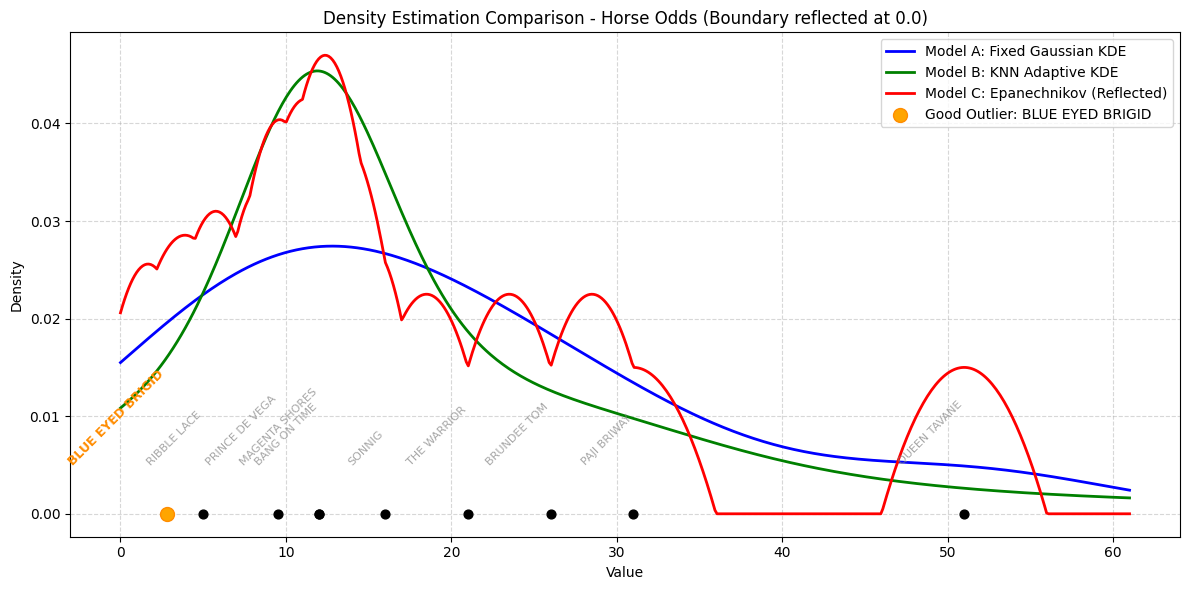

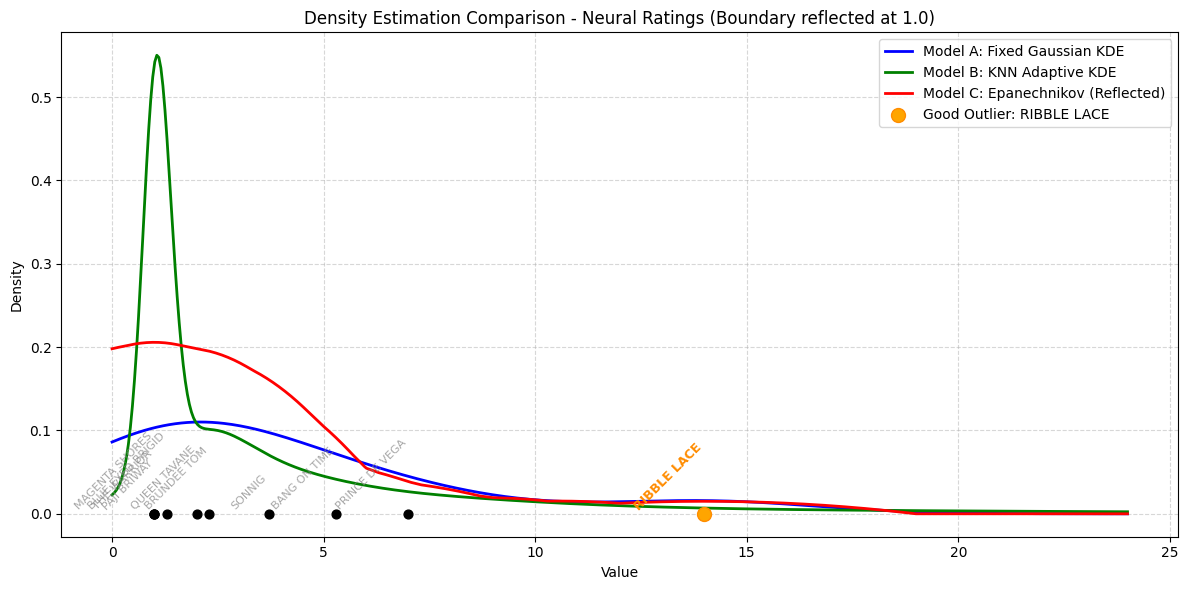

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
%matplotlib inline

# --- 1. DEFINE YOUR HORSE RACING DATA ---
# Example 1: Odds (Lower is better)
horses_ex1 = ["BANG ON TIME", "RIBBLE LACE", "BLUE EYED BRIGID", "PRINCE DE VEGA", "THE WARRIOR",
              "BRUNDEE TOM", "SONNIG", "QUEEN TAVANE", "MAGENTA SHORES", "PAJI BRIWAY"]
data_ex1 = np.array([12.0, 5.0, 2.8, 9.5, 21.0, 26.0, 16.0, 51.0, 12.0, 31.0])

# Example 2: Neural Ratings (Higher is better)
data_ex2 = np.array([5.3, 14.0, 1.3, 7.0, 1.0, 2.3, 3.7, 2.0, 1.0, 1.0])

def epanechnikov_reflected_kde(data, grid, bandwidth=3.0, lower_bound=0.0):
    """
    Evaluates Model C: Epanechnikov Kernel with Boundary Reflection at lower_bound.
    """
    density = np.zeros_like(grid)
    for x in data:
        # Original kernel
        u1 = (grid - x) / bandwidth
        k1 = 0.75 * (1 - u1**2) * (np.abs(u1) <= 1)

        # Reflected kernel across lower_bound
        x_reflected = 2 * lower_bound - x
        u2 = (grid - x_reflected) / bandwidth
        k2 = 0.75 * (1 - u2**2) * (np.abs(u2) <= 1)

        density += (k1 + k2) / (len(data) * bandwidth)
    return density

def knn_adaptive_kde(data, grid, k=3):
    """
    Evaluates Model B: Nearest-Neighbor Adaptive Gaussian KDE.
    """
    density = np.zeros_like(grid)
    for x in data:
        # Distance to kth nearest neighbor as local bandwidth
        dists = np.abs(data - x)
        dists.sort()
        local_bandwidth = dists[min(k, len(data)-1)]
        if local_bandwidth == 0:
            local_bandwidth = 1e-5

        # Gaussian kernel evaluation
        u = (grid - x) / local_bandwidth
        k_val = (1.0 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * u**2)
        density += k_val / (len(data) * local_bandwidth)
    return density

def evaluate_density_models(data, labels, title, boundary=0.0, highlight_best="lower"):
    grid = np.linspace(max(0.0, min(data) - 10), max(data) + 10, 500)

    # Model A: Fixed Gaussian KDE
    kde_fixed = gaussian_kde(data)
    density_a = kde_fixed(grid)

    # Model B: KNN Adaptive Gaussian KDE
    density_b = knn_adaptive_kde(data, grid, k=3)

    # Model C: Epanechnikov with Boundary Reflection
    density_c = epanechnikov_reflected_kde(data, grid, bandwidth=5.0, lower_bound=boundary)

    # Determine the "best" outlier index
    if highlight_best == "lower":
        best_idx = np.argmin(data)
    else:
        best_idx = np.argmax(data)

    # Plotting
    plt.figure(figsize=(12, 6))
    plt.plot(grid, density_a, label="Model A: Fixed Gaussian KDE", color="blue", lw=2)
    plt.plot(grid, density_b, label="Model B: KNN Adaptive KDE", color="green", lw=2)
    plt.plot(grid, density_c, label="Model C: Epanechnikov (Reflected)", color="red", lw=2)

    # Plot points and flag horse names to visually spot outliers
    for idx, (x, label) in enumerate(zip(data, labels)):
        if idx == best_idx:
            plt.scatter(x, 0, color='orange', edgecolor='darkorange', zorder=6, s=100, label=f"Good Outlier: {label}")
            plt.annotate(label, (x, 0.005), rotation=45, ha='right', fontsize=9, fontweight='bold', color='darkorange', alpha=1.0)
        else:
            plt.scatter(x, 0, color='black', zorder=5, s=40)
            plt.annotate(label, (x, 0.005), rotation=45, ha='right', fontsize=8, color='grey', alpha=0.7)

    plt.title(f"Density Estimation Comparison - {title}")
    plt.xlabel("Value")
    plt.ylabel("Density")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

# Run evaluation on both datasets, highlighting the "good" outlier accordingly
evaluate_density_models(data_ex1, horses_ex1, "Horse Odds (Boundary reflected at 0.0)", boundary=0.0, highlight_best="lower")
evaluate_density_models(data_ex2, horses_ex1, "Neural Ratings (Boundary reflected at 1.0)", boundary=1.0, highlight_best="higher")